In [1]:
import os
import pandas as pd

cdhit_dir = "../results/cdhit70"

cluster_summary = []
cluster_members = []

for file in os.listdir(cdhit_dir):

    if not file.endswith(".clstr"):
        continue

    architecture = (
        file
        .replace("_70.fasta.clstr", "")
    )

    filepath = os.path.join(cdhit_dir, file)

    current_cluster = None
    cluster_size = 0

    with open(filepath) as f:

        for line in f:

            line = line.strip()

            if line.startswith(">Cluster"):

                if current_cluster is not None:

                    cluster_summary.append({
                        "architecture": architecture,
                        "cluster": current_cluster,
                        "size": cluster_size
                    })

                current_cluster = int(
                    line.replace(">Cluster ", "")
                )

                cluster_size = 0

            else:

                cluster_size += 1

                protein = (
                    line.split(">")[1]
                    .split("...")[0]
                )

                representative = line.endswith("*")

                cluster_members.append({
                    "architecture": architecture,
                    "cluster": current_cluster,
                    "protein": protein,
                    "representative": representative
                })

        if current_cluster is not None:

            cluster_summary.append({
                "architecture": architecture,
                "cluster": current_cluster,
                "size": cluster_size
            })

cluster_df = pd.DataFrame(cluster_summary)
members_df = pd.DataFrame(cluster_members)

print(cluster_df.shape)
print(members_df.shape)

(191, 3)
(312, 4)


In [2]:
diversity_df = (
    cluster_df
    .groupby("architecture")
    .agg(
        clusters70=("cluster", "nunique"),
        proteins=("size", "sum"),
        largest_cluster=("size", "max")
    )
    .reset_index()
)

diversity_df["diversity_ratio"] = (
    diversity_df["clusters70"] /
    diversity_df["proteins"]
)

diversity_df.sort_values(
    "diversity_ratio",
    ascending=False
).head(20)

,architecture,clusters70,proteins,largest_cluster,diversity_ratio
1,AA1_3_AA1,1,1,1,1.0
2,AA2_AA5,1,1,1,1.0
4,AA9_CBM1,1,1,1,1.0
6,CBM1_GH45_1,1,1,1,1.0
5,CBM1_GH10,1,1,1,1.0
9,CBM87_CE18,3,3,1,1.0
8,CBM38_GH32,2,2,1,1.0
13,GH11_CBM1,1,1,1,1.0
14,GH128_GH16_4,1,1,1,1.0
10,CE1_CBM1,1,1,1,1.0


In [3]:
representatives = members_df[
    members_df["representative"]
]

representatives.head()

,architecture,cluster,protein,representative
2,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True
4,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True
5,AA1_3_AA1,0,tr|W6Q429|W6Q429_PENRF,True
6,AA2_AA5,0,tr|A0A698XLC6|A0A698XLC6_TALPI,True
7,AA8_AA3_1,0,tr|A0A1L9U833|A0A1L9U833_ASPBC,True


In [4]:
representatives["representative"].nunique()

1

In [5]:
diversity_df.sort_values(
    "diversity_ratio",
    ascending=False
)

,architecture,clusters70,proteins,largest_cluster,diversity_ratio
1,AA1_3_AA1,1,1,1,1.000000
2,AA2_AA5,1,1,1,1.000000
4,AA9_CBM1,1,1,1,1.000000
6,CBM1_GH45_1,1,1,1,1.000000
5,CBM1_GH10,1,1,1,1.000000
9,CBM87_CE18,3,3,1,1.000000
8,CBM38_GH32,2,2,1,1.000000
13,GH11_CBM1,1,1,1,1.000000
14,GH128_GH16_4,1,1,1,1.000000
10,CE1_CBM1,1,1,1,1.000000


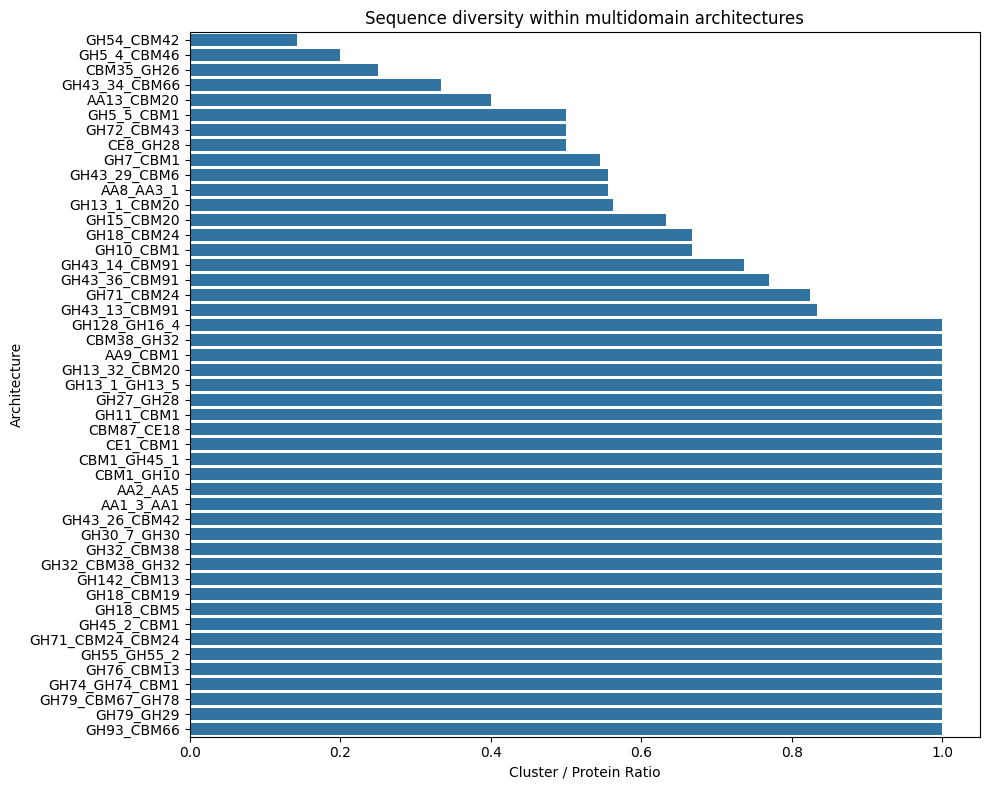

<Figure size 640x480 with 0 Axes>

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = diversity_df.sort_values(
    "diversity_ratio",
    ascending=True
)

plt.figure(figsize=(10,8))

sns.barplot(
    data=plot_df,
    x="diversity_ratio",
    y="architecture"
)

plt.xlabel("Cluster / Protein Ratio")
plt.ylabel("Architecture")
plt.title("Sequence diversity within multidomain architectures")

plt.tight_layout()

plt.savefig(
    "../results/figures/Sequence_diversity_within_multidomain_architectures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.tight_layout()
plt.show()

In [7]:
diversity_df["largest_cluster_fraction"] = (
    diversity_df["largest_cluster"]
    / diversity_df["proteins"]
)
diversity_df.sort_values(
    "largest_cluster_fraction"
)

,architecture,clusters70,proteins,largest_cluster,diversity_ratio,largest_cluster_fraction
40,GH72_CBM43,24,48,4,0.500000,0.083333
38,GH71_CBM24,28,34,4,0.823529,0.117647
28,GH43_14_CBM91,14,19,3,0.736842,0.157895
19,GH15_CBM20,19,30,5,0.633333,0.166667
3,AA8_AA3_1,15,27,5,0.555556,0.185185
15,GH13_1_CBM20,9,16,3,0.562500,0.187500
32,GH43_36_CBM91,10,13,3,0.769231,0.230769
25,GH32_CBM38,4,4,1,1.000000,0.250000
45,GH7_CBM1,6,11,3,0.545455,0.272727
30,GH43_29_CBM6,5,9,3,0.555556,0.333333


In [8]:

candidate_proteins = pd.read_csv(
    "../results/tables/candidate_proteins.csv"
)
members_species = members_df.merge(
    candidate_proteins[["species", "query"]],
    left_on="protein",
    right_on="query",
    how="left"
)

members_species.head()

,architecture,cluster,protein,representative,species,query
0,AA13_CBM20,0,tr|A1CN59|A1CN59_ASPCL,False,aspergillus_clavatus,tr|A1CN59|A1CN59_ASPCL
1,AA13_CBM20,0,sp|Q5B1W7|AA13_EMENI,False,aspergillus_nidulans,sp|Q5B1W7|AA13_EMENI
2,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True,penicillium_oxalicum,tr|S8AKS0|S8AKS0_PENO1
3,AA13_CBM20,1,tr|A0A8T8WTI5|A0A8T8WTI5_ASPJA,False,aspergillus_japonicus,tr|A0A8T8WTI5|A0A8T8WTI5_ASPJA
4,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True,neurospora_crassa,sp|Q7SCE9|AA13_NEUCR


In [9]:
members_species.columns


Index(['architecture', 'cluster', 'protein', 'representative', 'species',
       'query'],
      dtype='str')

In [10]:
members_species["species"].isna().sum()

np.int64(0)

In [11]:
cluster_species = (
    members_species
    .groupby(["architecture", "cluster"])
    .agg(
        proteins=("protein", "count"),
        species=("species", "nunique")
    )
    .reset_index()
)

cluster_species.head()

,architecture,cluster,proteins,species
0,AA13_CBM20,0,3,3
1,AA13_CBM20,1,2,2
2,AA1_3_AA1,0,1,1
3,AA2_AA5,0,1,1
4,AA8_AA3_1,0,2,2


In [12]:
cluster_species["species_fraction"] = (
    cluster_species["species"]
    / cluster_species["proteins"]
)
cluster_species.sort_values(
    ["species", "proteins"],
    ascending=False
).head(30)

,architecture,cluster,proteins,species,species_fraction
119,GH54_CBM42,1,20,13,0.65
8,AA8_AA3_1,4,5,5,1.00
55,GH15_CBM20,5,5,5,1.00
120,GH54_CBM42,2,5,5,1.00
123,GH5_4_CBM46,0,5,5,1.00
22,CBM35_GH26,0,4,4,1.00
57,GH15_CBM20,7,4,4,1.00
149,GH71_CBM24,23,4,4,1.00
156,GH72_CBM43,1,4,4,1.00
158,GH72_CBM43,3,4,4,1.00


In [13]:
arch_cluster_stats = (
    cluster_species
    .groupby("architecture")
    .agg(
        mean_cluster_size=("proteins", "mean"),
        mean_species=("species", "mean"),
        max_species=("species", "max")
    )
    .reset_index()
)

arch_cluster_stats

,architecture,mean_cluster_size,mean_species,max_species
0,AA13_CBM20,2.500000,2.500000,3
1,AA1_3_AA1,1.000000,1.000000,1
2,AA2_AA5,1.000000,1.000000,1
3,AA8_AA3_1,1.800000,1.800000,5
4,AA9_CBM1,1.000000,1.000000,1
5,CBM1_GH10,1.000000,1.000000,1
6,CBM1_GH45_1,1.000000,1.000000,1
7,CBM35_GH26,4.000000,4.000000,4
8,CBM38_GH32,1.000000,1.000000,1
9,CBM87_CE18,1.000000,1.000000,1


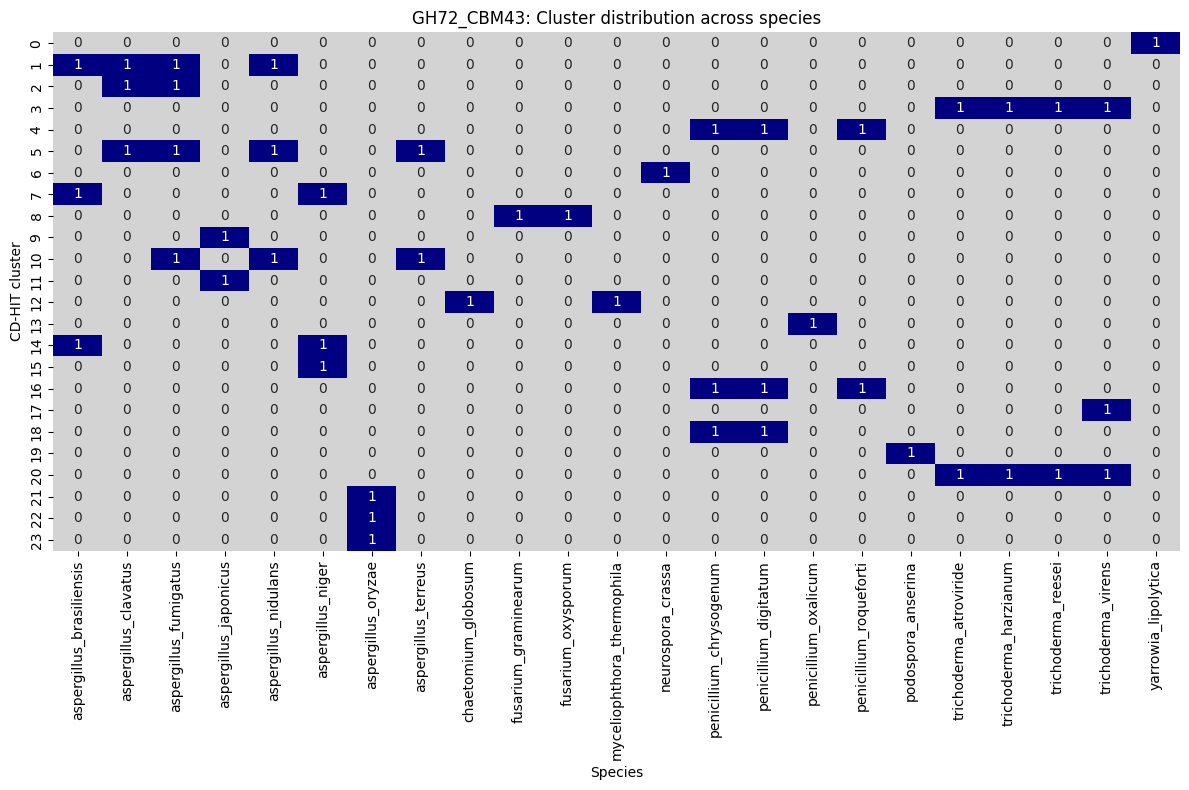

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

#Figure  Cluster × Species heatmap
arch = "GH72_CBM43"

plot_df = members_species[
    members_species["architecture"] == arch
]

heatmap_df = (
    plot_df
    .groupby(["cluster","species"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12,8))

sns.heatmap(
    heatmap_df,
    cmap=["lightgrey", "navy"],
    annot=True,
    fmt="d",
    cbar=False
)

plt.title(
    f"{arch}: Cluster distribution across species"
)

plt.savefig(
    "../results/figures/gh72__CBM43_cluster_presence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.xlabel("Species")
plt.ylabel("CD-HIT cluster")

plt.tight_layout()

plt.show()

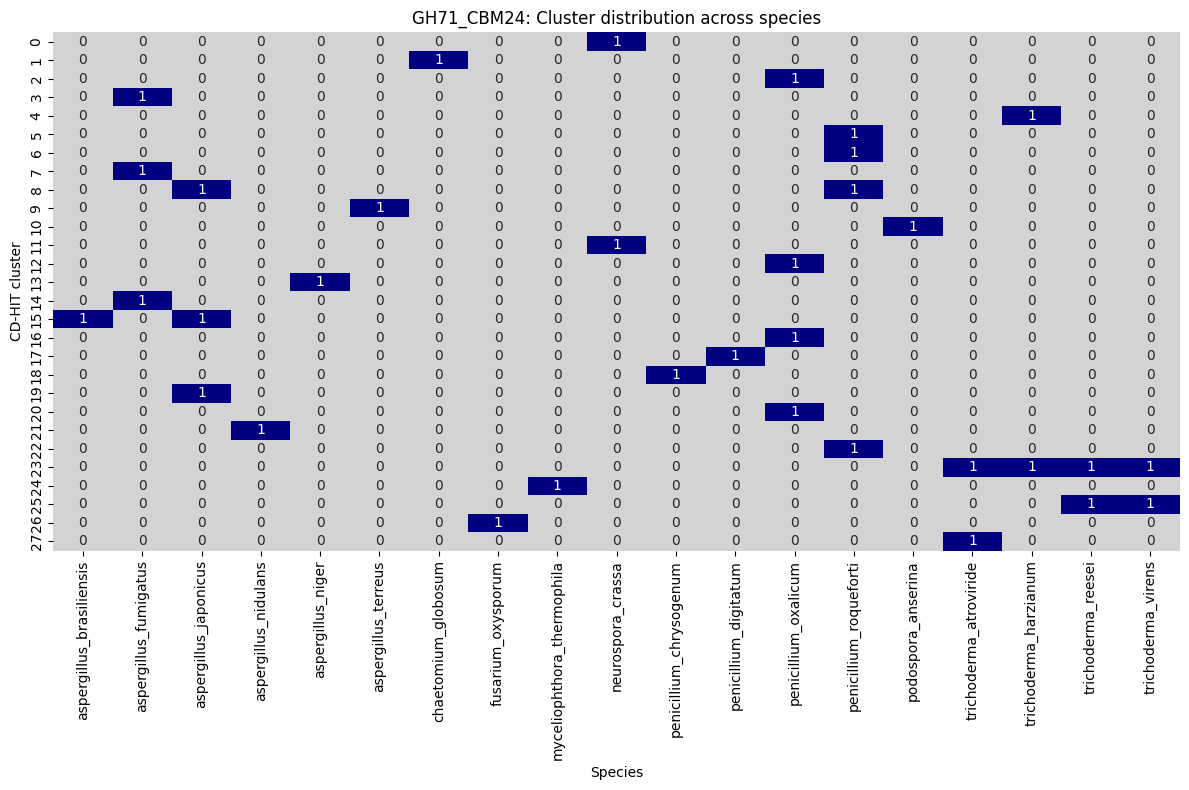

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

#Figure  Cluster × Species heatmap
arch = "GH71_CBM24"

plot_df = members_species[
    members_species["architecture"] == arch
]

heatmap_df = (
    plot_df
    .groupby(["cluster","species"])
    .size()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12,8))

sns.heatmap(
    heatmap_df,
    cmap=["lightgrey", "navy"],
    annot=True,
    fmt="d",
    cbar=False
)

plt.title(
    f"{arch}: Cluster distribution across species"
)

plt.savefig(
    "../results/figures/GH71_CBM24_cluster_presence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.xlabel("Species")
plt.ylabel("CD-HIT cluster")

plt.tight_layout()

plt.show()

In [16]:
#Figure Cluster composition

cluster_sizes = (
    members_species[
        members_species["architecture"] == "GH72_CBM43"
    ]
    .groupby("cluster")
    .size()
    .sort_values(ascending=False)
)

cluster_sizes


cluster
1     4
3     4
5     4
20    4
10    3
16    3
4     3
7     2
14    2
18    2
2     2
8     2
12    2
0     1
6     1
11    1
15    1
13    1
9     1
17    1
19    1
21    1
22    1
23    1
dtype: int64

Text(0.5, 1.0, 'Sequence diversity of multidomain architectures')

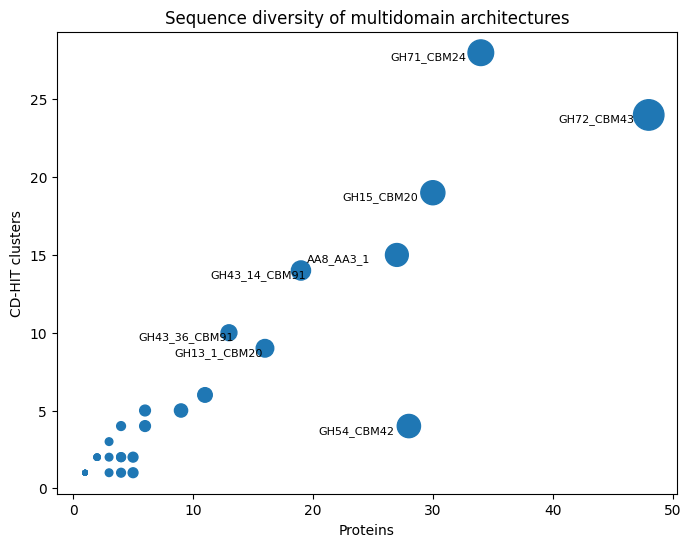

In [27]:
plt.figure(figsize=(8,6))

plt.scatter(
    diversity_df["proteins"],
    diversity_df["clusters70"],
    s=diversity_df["proteins"]*10
)

for _, row in diversity_df.iterrows():
    if row["proteins"] >= 12:
        '''plt.text(
            row["proteins"],
            row["clusters70"],
            row["architecture"],
        )'''
        plt.annotate(
        row["architecture"],
        (row["proteins"], row["clusters70"]),
        xytext=(-65,-5),
        textcoords="offset points",
        fontsize=8
        )



plt.savefig(
    "../results/figures/Sequence_diversity_of_multidomain_architectures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.xlabel("Proteins")
plt.ylabel("CD-HIT clusters")
plt.title("Sequence diversity of multidomain architectures")

In [18]:
#Figure Species richness of clusters

In [19]:
#Figure Species richness of clusters
cluster_summary = (
    members_species
    .groupby(["architecture","cluster"])
    .agg(
        proteins=("protein","count"),
        species=("species","nunique")
    )
    .reset_index()
)
plot_df = cluster_summary[
    cluster_summary["architecture"] == "GH72_CBM43"
]


In [21]:
cluster_info = (
    cluster_species
    .rename(columns={
        "proteins": "cluster_size",
        "species": "species_in_cluster"
    })
)
representatives_full = (
    representatives
    .merge(
        members_species[
            ["architecture", "cluster", "protein", "species"]
        ],
        on=["architecture", "cluster", "protein"],
        how="left"
    )
    .merge(
        cluster_info,
        on=["architecture", "cluster"],
        how="left"
    )
)
representatives_full.to_csv(
    "../results/tables/architecture_representatives.csv",
    index=False
)

In [22]:
representatives_full

,architecture,cluster,protein,representative,species,cluster_size,species_in_cluster,species_fraction
0,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True,penicillium_oxalicum,3,3,1.0
1,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True,neurospora_crassa,2,2,1.0
2,AA1_3_AA1,0,tr|W6Q429|W6Q429_PENRF,True,penicillium_roqueforti,1,1,1.0
3,AA2_AA5,0,tr|A0A698XLC6|A0A698XLC6_TALPI,True,talaromyces_pinophilus,1,1,1.0
4,AA8_AA3_1,0,tr|A0A1L9U833|A0A1L9U833_ASPBC,True,aspergillus_brasiliensis,2,2,1.0
...,...,...,...,...,...,...,...,...
186,GH7_CBM1,2,tr|G2Q665|G2Q665_THET4,True,myceliophthora_thermophila,3,3,1.0
187,GH7_CBM1,3,tr|A0A8H6ZYZ4|A0A8H6ZYZ4_PLEOS,True,pleurotus_ostreatus,2,1,0.5
188,GH7_CBM1,4,tr|A0A5M3Z9H2|A0A5M3Z9H2_ASPTE,True,aspergillus_terreus,2,2,1.0
189,GH7_CBM1,5,tr|G2R8K6|G2R8K6_THETT,True,thielavia_terrestris,1,1,1.0


In [24]:
members_species.to_csv(
    "../results/tables/cluster_members.csv",
    index=False
)

In [25]:
members_species

,architecture,cluster,protein,representative,species,query
0,AA13_CBM20,0,tr|A1CN59|A1CN59_ASPCL,False,aspergillus_clavatus,tr|A1CN59|A1CN59_ASPCL
1,AA13_CBM20,0,sp|Q5B1W7|AA13_EMENI,False,aspergillus_nidulans,sp|Q5B1W7|AA13_EMENI
2,AA13_CBM20,0,tr|S8AKS0|S8AKS0_PENO1,True,penicillium_oxalicum,tr|S8AKS0|S8AKS0_PENO1
3,AA13_CBM20,1,tr|A0A8T8WTI5|A0A8T8WTI5_ASPJA,False,aspergillus_japonicus,tr|A0A8T8WTI5|A0A8T8WTI5_ASPJA
4,AA13_CBM20,1,sp|Q7SCE9|AA13_NEUCR,True,neurospora_crassa,sp|Q7SCE9|AA13_NEUCR
...,...,...,...,...,...,...
307,GH7_CBM1,3,tr|A0A8H7A0E7|A0A8H7A0E7_PLEOS,False,pleurotus_ostreatus,tr|A0A8H7A0E7|A0A8H7A0E7_PLEOS
308,GH7_CBM1,4,tr|B0YDR8|B0YDR8_ASPFC,False,aspergillus_fumigatus,tr|B0YDR8|B0YDR8_ASPFC
309,GH7_CBM1,4,tr|A0A5M3Z9H2|A0A5M3Z9H2_ASPTE,True,aspergillus_terreus,tr|A0A5M3Z9H2|A0A5M3Z9H2_ASPTE
310,GH7_CBM1,5,tr|G2R8K6|G2R8K6_THETT,True,thielavia_terrestris,tr|G2R8K6|G2R8K6_THETT
